# Module 4 – Pipeline, baselines et évaluation

Objectif : une première version qui tourne de bout en bout.
1. Assembler la cible et les variables (modules 2 et 3), pour chaque T = 0, 7, 30, 90.
2. Construire un pipeline scikit-learn (imputation + normalisation **dans** le pipeline, ajusté sur le train seulement).
3. Comparer deux baselines sur la **validation** : `DummyClassifier` et régression logistique.

**Le test n'est jamais utilisé ici.** Il ne servira qu'une seule fois, à la toute fin, pour le modèle final.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, confusion_matrix)
from config import *

games = pd.read_parquet(PROC_DIR / "games_clean.parquet", columns=["app_id", "release_date"])
reviews = pd.read_parquet(PROC_DIR / "reviews_clean.parquet", columns=["app_id", "days", "is_recommended"])
static = pd.read_parquet(PROC_DIR / "features_static.parquet")
print("Jeux :", len(games), "| Variables statiques :", static.shape)

Jeux : 10000 | Variables statiques : (10000, 218)


## 1. Cible temporaire

Le module 2 n'a pas encore livré `target.parquet`. Pour avancer, on applique **sa règle** (voir `REPARTITION_MODULES.md`) :
- `n_reviews_1y`, `pos_ratio_1y` : nombre et part d'avis positifs pendant la première année (`days < 365`). Jointure `left` depuis tous les jeux : un jeu sans avis a 0 avis, il n'est pas supprimé.
- découpage par date de sortie : 70 % les plus anciens en train, 15 % en validation, 15 % en test (même règle que le module 3) ;
- seuil du top 20 % en nombre d'avis, calculé **sur le train seulement** ;
- `success` = (`n_reviews_1y` ≥ seuil) **et** (`pos_ratio_1y` ≥ 80 %).

⚠️ Dès que `target.parquet` existe, on remplace les deux cellules suivantes par sa lecture.

In [2]:
# Tous les jeux ont une année complète d'avis (dernier avis : 31/12/2022, dernière sortie : 31/12/2021)
assert (games["release_date"] + pd.Timedelta(days=HORIZON_DAYS)).max() <= pd.Timestamp("2022-12-31")

year1 = reviews[reviews["days"] < HORIZON_DAYS]  # avis de la première année
counts = year1.groupby("app_id").agg(
    n_reviews_1y=("is_recommended", "size"),
    pos_ratio_1y=("is_recommended", "mean"),
)
target = games.merge(counts, on="app_id", how="left")  # left : les jeux sans avis sont gardés
target["n_reviews_1y"] = target["n_reviews_1y"].fillna(0)

rank = target["release_date"].rank(method="first") / len(target)
target["split"] = np.where(rank <= SPLIT[0], "train",
                  np.where(rank <= SPLIT[0] + SPLIT[1], "val", "test"))

In [3]:
threshold = target.loc[target["split"] == "train", "n_reviews_1y"].quantile(TOP_QUANTILE)  # TRAIN seulement
target["success"] = (target["n_reviews_1y"] >= threshold) & (target["pos_ratio_1y"] >= MIN_POS_RATIO)

print("Seuil du top 20 % (train) :", threshold, "avis la première année")
target.groupby("split")["success"].agg(["count", "sum", "mean"])

Seuil du top 20 % (train) : 66.0 avis la première année


,count,sum,mean
split,,,
test,1500,223,0.148667
train,7000,923,0.131857
val,1500,235,0.156667


Un jeu sans avis a `pos_ratio_1y` vide : la comparaison `>= 0.8` donne False, donc ce n'est pas un succès. C'est le comportement voulu.

Les succès sont **rares** (environ 1 jeu sur 7) : l'accuracy n'a pas de sens ici. Un modèle qui répond toujours « pas un succès » aurait environ 85 % d'accuracy sans rien apprendre. On utilise donc la **PR-AUC** comme métrique principale.

## 2. Un jeu de données par valeur de T

- T = 0 : variables statiques seules.
- T = 7, 30, 90 : variables statiques + signaux précoces de `features_T{T}.parquet`.

`desc_length` et `n_reviews` sont très asymétriques (module 3) : on les passe au log. C'est une transformation ligne par ligne, sans rien apprendre sur les données, donc sans risque de fuite. Elle peut être faite avant le découpage.

In [4]:
def make_dataset(T):
    df = target[["app_id", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df

make_dataset(30).shape

(10000, 223)

## 3. Pipeline

- Variables numériques (`NUM_COLS`) : valeurs manquantes remplacées par la **médiane**, puis **normalisation** (moyenne 0, écart-type 1).
- Mois et jour de sortie (`CAT_COLS`) : ce sont des **catégories**, pas des quantités. Décembre (12) n'est pas « 12 fois » janvier (1), et pour une régression logistique, un effet linéaire du mois n'a pas de sens. `OneHotEncoder` crée une colonne 0/1 par mois et par jour.
- Les autres colonnes sont déjà en 0/1 (plateformes, genres, tags, `in_fronkon`, `has_reviews`) : elles passent telles quelles (`remainder="passthrough"`).

La médiane et la normalisation sont **calculées pendant `fit`, donc sur le train seulement**, puis appliquées à la validation. Les calculer sur toutes les données ferait fuiter de l'information de la validation dans l'entraînement : c'est l'erreur qui plafonne la note à 10/20.

In [5]:
NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]

def make_model(clf, num_cols):
    preprocess = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),  # une colonne 0/1 par mois et par jour
        remainder="passthrough",  # colonnes 0/1 : inchangées
    )
    return make_pipeline(preprocess, clf)

## 4. Baselines et métriques sur la validation

- `DummyClassifier(strategy="most_frequent")` : répond toujours « pas un succès ». C'est le minimum à battre.
- `LogisticRegression(class_weight="balanced")` : donne plus de poids aux succès, qui sont rares, pour que le modèle ne les ignore pas.

Métriques, calculées sur les **probabilités** (`predict_proba`) pour la PR-AUC et la ROC-AUC, et sur les classes prédites (seuil 0,5) pour F1, précision et rappel :
- **PR-AUC (principale)** : qualité du classement des succès. Un modèle au hasard obtient la proportion de succès ;
- ROC-AUC : 0,5 = hasard, 1 = parfait ;
- précision : parmi les jeux prédits « succès », la part de vrais succès ; rappel : parmi les vrais succès, la part trouvée.

In [6]:
def evaluate(model, X, y):
    proba = model.predict_proba(X)[:, 1]  # probabilité d'être un succès
    pred = proba >= 0.5
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "F1": f1_score(y, pred, zero_division=0),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
    }

results = []
logreg_models = {}  # régression logistique entraînée pour chaque T (pour lire ses coefficients)
for T in T_VALUES:
    df = make_dataset(T)
    train, val = df[df["split"] == "train"], df[df["split"] == "val"]  # le test n'est pas utilisé
    X_train, y_train = train.drop(columns=["app_id", "split", "success"]).astype(float), train["success"]
    X_val, y_val = val.drop(columns=["app_id", "split", "success"]).astype(float), val["success"]
    num_cols = [c for c in NUM_COLS if c in X_train.columns]  # n_reviews et pos_ratio seulement si T > 0

    for name, clf in [("Dummy", DummyClassifier(strategy="most_frequent")),
                      ("LogReg", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]:
        model = make_model(clf, num_cols).fit(X_train, y_train)
        results.append({"model": name, "T": T, **evaluate(model, X_val, y_val)})
    logreg_models[T] = model  # le dernier modèle de la boucle est la régression logistique

    print(f"T = {T:>2} | matrice de confusion LogReg (lignes = vrai, colonnes = prédit) :")
    print(confusion_matrix(y_val, model.predict(X_val)))

results = pd.DataFrame(results)
print("PR-AUC d'un modèle au hasard (proportion de succès en validation) :", round(y_val.mean(), 3))
results.round(3)

T =  0 | matrice de confusion LogReg (lignes = vrai, colonnes = prédit) :
[[937 328]
 [ 89 146]]
T =  7 | matrice de confusion LogReg (lignes = vrai, colonnes = prédit) :
[[1078  187]
 [  45  190]]
T = 30 | matrice de confusion LogReg (lignes = vrai, colonnes = prédit) :
[[1098  167]
 [  31  204]]
T = 90 | matrice de confusion LogReg (lignes = vrai, colonnes = prédit) :
[[1116  149]
 [  29  206]]
PR-AUC d'un modèle au hasard (proportion de succès en validation) : 0.157


,model,T,PR-AUC,ROC-AUC,F1,precision,recall
0,Dummy,0,0.157,0.500,0.000,0.000,0.000
1,LogReg,0,0.411,0.766,0.412,0.308,0.621
2,Dummy,7,0.157,0.500,0.000,0.000,0.000
3,LogReg,7,0.746,0.919,0.621,0.504,0.809
4,Dummy,30,0.157,0.500,0.000,0.000,0.000
5,LogReg,30,0.812,0.944,0.673,0.550,0.868
6,Dummy,90,0.157,0.500,0.000,0.000,0.000
7,LogReg,90,0.850,0.960,0.698,0.580,0.877


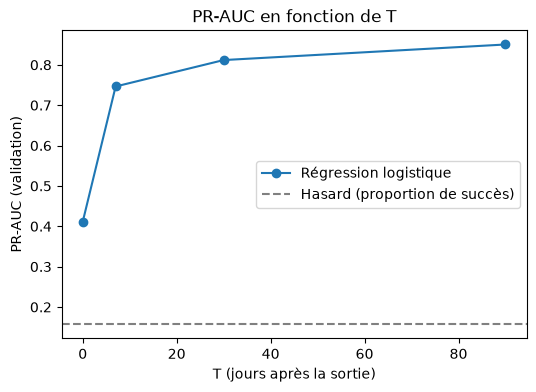

In [7]:
results.to_csv(ROOT / "report" / "results.csv", index=False)

logreg = results[results["model"] == "LogReg"]
plt.figure(figsize=(6, 4))
plt.plot(logreg["T"], logreg["PR-AUC"], marker="o", label="Régression logistique")
plt.axhline(y_val.mean(), color="gray", linestyle="--", label="Hasard (proportion de succès)")
plt.xlabel("T (jours après la sortie)")
plt.ylabel("PR-AUC (validation)")
plt.title("PR-AUC en fonction de T")
plt.legend()
plt.show()

**Lecture :**
- **Le Dummy a une PR-AUC de 0,157**, exactement la proportion de succès en validation : c'est le niveau du hasard. Son F1 est 0, car il ne prédit jamais un succès.
- **À T = 0, la régression logistique fait 2,6 fois mieux que le hasard** (PR-AUC 0,411, ROC-AUC 0,77), avec seulement les informations connues à la sortie. Elle trouve 62 % des succès (146 sur 235), mais avec beaucoup de fausses alertes : 328 jeux prédits « succès » à tort, d'où une précision de 31 %.
- **Les premiers avis changent tout : de 0,411 à 0,746 dès T = 7.** Ensuite, le gain ralentit : 0,812 à T = 30, 0,850 à T = 90. L'essentiel de l'information arrive dans la première semaine.
- **À T = 30, 204 succès sur 235 sont trouvés** (rappel 87 %), pour 167 fausses alertes (précision 55 %). Le seuil de 0,5 avec `class_weight="balanced"` favorise le rappel.
- **Attention à l'interprétation pour T > 0 :** la cible compte les avis de la première année, et les avis des T premiers jours en font partie. Une partie du score est donc mécanique. Ce n'est pas une fuite (ces avis sont bien connus à T), mais à T = 90, le modèle a déjà vu un quart de la période qui définit la cible.

**Historique des scores à T = 0** (PR-AUC sur la validation) :
- 0,442 avec la première version ;
- 0,435 avec le mois et le jour en *one-hot* (AI_AUDIT, Flaw 4) : pas de vrai changement ;
- **0,411 après le retrait des catégories ajoutées après la sortie** (module 3, AI_AUDIT, Flaw 5).

La baisse de 0,435 à 0,411 est attendue : une partie du score venait d'informations qu'on n'a pas à la sortie. 0,411 est le score **honnête**. Pour T ≥ 7, rien ne change (0,746 / 0,812 / 0,850) : les premiers avis apportent beaucoup plus d'information que ces catégories.

Ces scores n'ont pas encore d'intervalle de confiance : le bootstrap du module 2 dira si un écart de 0,01 ou 0,02 est significatif.

## 5. Choix du modèle de base

À cette étape, on ne cherche pas le meilleur modèle : on choisit une **référence**, que les modèles suivants devront battre. On vérifie d'abord qu'on peut lire ce que la régression logistique a appris. Les variables numériques sont normalisées, donc leurs coefficients sont comparables entre eux : un coefficient positif augmente la probabilité de succès, un coefficient négatif la diminue.

In [8]:
# Coefficients de la régression logistique à T = 0 (seulement les informations connues à la sortie)
model_T0 = logreg_models[0]
names = model_T0[0].get_feature_names_out()  # étape 0 du pipeline : le préprocesseur (noms préfixés
                                             # par pipeline__, onehotencoder__ ou remainder__)
coefs = pd.Series(model_T0[-1].coef_[0], index=names).sort_values()  # dernière étape : le modèle

print("8 variables qui diminuent le plus la probabilité de succès, puis 8 qui l'augmentent le plus :")
pd.concat([coefs.head(8), coefs.tail(8)]).round(2)

8 variables qui diminuent le plus la probabilité de succès, puis 8 qui l'augmentent le plus :


remainder__genre_Violent          -2.12
remainder__win                    -1.27
remainder__cat_MMO                -1.20
remainder__tag_Text-Based         -1.16
remainder__tag_Abstract           -0.98
remainder__tag_Combat             -0.97
remainder__tag_Top-Down Shooter   -0.93
remainder__tag_Sports             -0.92
remainder__tag_Detective           0.88
remainder__genre_Sports            0.88
remainder__tag_Multiplayer         0.89
remainder__cat_Online Co-op        1.03
remainder__tag_Visual Novel        1.08
remainder__tag_Utilities           1.25
remainder__is_free                 1.47
remainder__tag_Hentai              1.56
dtype: float64

**Lecture des coefficients (T = 0) :**

Pour une variable 0/1 (tag, genre, plateforme), le coefficient est l'effet d'avoir ce tag, **les autres variables étant fixées**. Ce sont des associations, pas des causes.

- **Des signaux cohérents avec la cible** (beaucoup d'avis **et** ≥ 80 % positifs). Les niches avec un public fidèle et enthousiaste poussent vers le succès : `Visual Novel` (33,6 % de succès dans le train), `Detective` (34,7 %), `Hentai` (56,0 %), contre 13,2 % en moyenne. À l'inverse, `genre_Violent` (0 succès sur 74 jeux du train), `MMO` (5,0 %) et `Text-Based` (6,6 %) en éloignent : les MMO reçoivent beaucoup d'avis négatifs.
- **Une fuite détectée grâce aux coefficients.** Dans la première version, `cat_Remote Play on Tablet` faisait partie des plus forts coefficients positifs (+1,17), avec 66,7 % de succès dans le train. En vérifiant, on a trouvé 9 catégories Steam ajoutées **après** la sortie (Remote Play, Family Sharing, Steam Trading Cards, accessibilité). Elles ont été retirées dans le module 3 (AI_AUDIT, Flaw 5). Il n'en reste plus dans le top ci-dessus.
- **Prudence sur certains coefficients**, qui ne disent pas la même chose que le taux de succès brut :
  - `win` (98,4 % des jeux) a un coefficient de −1,27, alors que les jeux Windows ont plus de succès (13,4 % contre 2,7 %). Une variable presque constante a un coefficient instable, qui ne veut rien dire.
  - `tag_Sports` (−0,92) et `genre_Sports` (+0,88) décrivent presque la même chose, mais ont des signes opposés. Quand deux variables sont très liées, le modèle répartit l'effet entre elles de façon arbitraire : on ne peut pas lire chaque coefficient seul.
  - Les plus gros coefficients concernent des tags **rares** (70 à 120 jeux, autour du seuil de 1 %). Le modèle leur donne beaucoup de poids à partir de peu d'exemples : la régularisation (`C`) devra être réglée sur la validation à l'étape suivante.
- **Aucune variable numérique dans le top 16** : à T = 0, ce sont surtout le type de jeu et ses tags qui comptent, plus que le prix ou le nombre de langues.

### Modèle de base retenu : la régression logistique

| Critère | Pourquoi la régression logistique |
|---|---|
| **Elle bat clairement le minimum** | PR-AUC de 0,411 à T = 0 et de 0,812 à T = 30, contre 0,157 pour le Dummy (le hasard), à tous les T. Le problème est donc apprenable avec nos variables. |
| **Elle est interprétable** | Un coefficient par variable : on peut expliquer ce qui pousse vers le succès. C'est ce qui nous a permis de **détecter la fuite des catégories ajoutées après la sortie**. |
| **Une seule vraie décision de réglage** | La régularisation `C`, laissée par défaut ici. C'est une référence simple et reproductible (`random_state=SEED`). |
| **Elle gère le déséquilibre** | `class_weight="balanced"` donne plus de poids aux succès (1 jeu sur 7), sans rééchantillonnage. |
| **Elle donne des probabilités** | `predict_proba` permet de calculer la PR-AUC et de choisir un seuil de décision plus tard, sur la validation. |
| **Rapide et vue en cours** | Elle s'entraîne en quelques secondes sur 7 000 jeux et environ 240 variables. |

Le **Dummy** n'est pas un candidat : c'est le **plancher**, qui montre ce que vaut un modèle qui n'apprend rien.

**Limites connues, à traiter à l'étape suivante :**
- le modèle est linéaire : il ne capte ni les seuils (« au-delà de 50 avis à T = 7, le succès est très probable ») ni les interactions (« tag Indie **et** gratuit »). C'est ce que les modèles suivants (random forest, gradient boosting) devront apporter ;
- la régularisation `C` n'est pas réglée, d'où les gros coefficients sur des tags rares et les signes instables entre variables liées.

Un modèle plus complexe ne sera retenu que s'il bat cette référence sur la **validation**, avec un écart supérieur à l'intervalle de confiance.

**Fichiers produits :** `report/results.csv` (Dummy et régression logistique pour T = 0, 7, 30, 90), le tableau de référence des prochaines étapes.